In [1]:
!pip install kagglehub
import kagglehub
path = kagglehub.dataset_download("gpiosenka/cards-image-datasetclassification")
print("Path ke dataset:", path)

Path ke dataset: /kaggle/input/datasets/gpiosenka/cards-image-datasetclassification


In [2]:
import os
os.listdir(path)
from torchvision import datasets
train_dir = os.path.join(path, 'train')
test_dir = os.path.join(path, 'test')
valid_dir = os.path.join(path, 'valid')
train_dataset = datasets.ImageFolder(root=train_dir)
test_dataset = datasets.ImageFolder(root=test_dir)
valid_dataset = datasets.ImageFolder(root=valid_dir)


In [3]:
from PIL import Image
import os
first_class = os.listdir(train_dir)[0]
folder_kelas = os.path.join(train_dir, first_class)
daftar_file = os.listdir(folder_kelas)
first_image_path = os.path.join(folder_kelas, daftar_file[0])
with Image.open(first_image_path) as img:
    width, height = img.size
    print(f"Ukuran gambar contoh: {width} x {height} piksel")

Ukuran gambar contoh: 224 x 224 piksel


In [4]:
import torchvision.transforms as transforms
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])
train_dataset = datasets.ImageFolder(root=train_dir,transform=transform)
test_dataset = datasets.ImageFolder(root=test_dir,transform=transform)
valid_dataset = datasets.ImageFolder(root=valid_dir,transform=transform)

In [5]:
from torch.utils.data import DataLoader
train_loader = DataLoader(dataset=train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(dataset=test_dataset, batch_size=32, shuffle=False)
val_loader = DataLoader(dataset=valid_dataset, batch_size=32, shuffle=False)

In [6]:
images, labels = next(iter(train_loader))
print(f"Ukuran batch gambar setelah resize: {images.shape}")

Ukuran batch gambar setelah resize: torch.Size([32, 3, 128, 128])


In [7]:
import torch
import torch.nn as nn
import torch.optim as optim
class CNN(nn.Module):
    def __init__(self, num_classes=53):
        super(CNN, self).__init__()
        self.features = nn.Sequential(
            #input channel, output_channel, kernel_size, stride, padding
            nn.Conv2d(3, 64, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(64, 256, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(256, 1024, kernel_size=3, stride=1, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Flatten()
        ) 
        self.classifier = nn.Sequential(
            nn.Linear(1024* 16 * 16, 2048),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(2048, 512),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(512, num_classes)
        )
    #def forward akan dijalankan kita ngecall modul nn.Module 
    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x 



In [8]:
from tqdm.notebook import tqdm
num_epochs = 10
train_losses, val_losses = [], []
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model = CNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)
for epoch in range(num_epochs):
    # Training phase
    model.train()
    running_loss = 0.0
    for images, labels in tqdm(train_loader, desc=f'Epoch {epoch+1} Training'):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * labels.size(0)
    train_loss = running_loss / len(train_loader.dataset)
    train_losses.append(train_loss)
    
    # Validation phase
    model.eval()
    val_running_loss = 0.0
    with torch.no_grad():
        for images, labels in tqdm(val_loader, desc=f'Epoch {epoch+1} Validation'):
            # Move inputs and labels to the device
            images, labels = images.to(device), labels.to(device)
         
            outputs = model(images)
            loss = criterion(outputs, labels)
            val_running_loss += loss.item() * labels.size(0)
    val_loss = val_running_loss / len(val_loader.dataset)
    val_losses.append(val_loss)
    print(f"Epoch {epoch+1} - Train Loss: {train_loss:.4f}, Val Loss: {val_loss:.4f}") 

Epoch 1 Training:   0%|          | 0/239 [00:00<?, ?it/s]

Epoch 1 Validation:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 1 - Train Loss: 4.0792, Val Loss: 3.9716


Epoch 2 Training:   0%|          | 0/239 [00:00<?, ?it/s]

Epoch 2 Validation:   0%|          | 0/9 [00:00<?, ?it/s]

...

Epoch 9 Validation:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 9 - Train Loss: 3.9650, Val Loss: 3.9760


Epoch 10 Training:   0%|          | 0/239 [00:00<?, ?it/s]

Epoch 10 Validation:   0%|          | 0/9 [00:00<?, ?it/s]

Epoch 10 - Train Loss: 3.9650, Val Loss: 3.9764


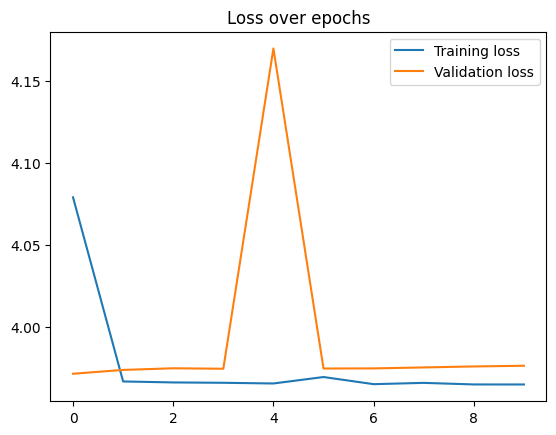

In [9]:
import matplotlib.pyplot as plt

plt.plot(train_losses, label='Training loss')
plt.plot(val_losses, label='Validation loss')
plt.legend()
plt.title("Loss over epochs")
plt.show()

In [10]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
def preprocess_image(image_path, transform):
    image = Image.open(image_path).convert("RGB")
    return image, transform(image).unsqueeze(0)
def predict(model, image_tensor, device):
    model.eval()
    with torch.no_grad():
        image_tensor = image_tensor.to(device)
        outputs = model(image_tensor)
        probabilities = torch.nn.functional.softmax(outputs, dim=1)
        max_prob,predicted_class= torch.max(probabilities, dim=1)
    return predicted_class.item(), max_prob.item()
def test(image_path,model,device,transform,class_names):
    image, image_tensor = preprocess_image(image_path, transform)
    predicted_class, max_prob = predict(model, image_tensor, device)
    nama_kartu=class_names[predicted_class]
    plt.figure(figsize=(10, 5))
    plt.subplot(1, 2, 1)
    plt.imshow(image)
    plt.title(f"prediksi: {nama_kartu} dengan keyakinan{max_prob*100:.2f}%")
    plt.axis('off')
    plt.show()
    return nama_kartu,max_prob


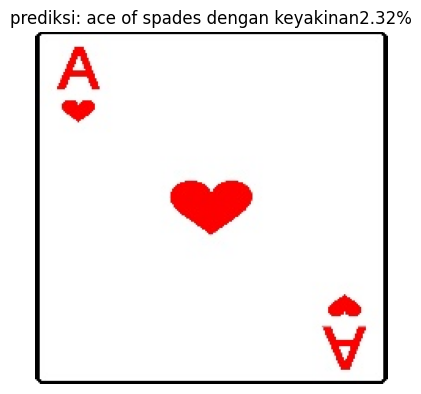

('ace of spades', 0.023205893114209175)

In [11]:
kelas_test = test_dataset.classes
test_path=test_dataset.imgs[10][0]# mengambil dataset ke 10
test(test_path, model, device, transform, kelas_test)

In [12]:
!pip install onnxscript onnx
import torch
import os

def save_models(model, dummy_input, pth_name, onnx_name):
    # 1. Simpan format PyTorch (.pth)
    torch.save(model.state_dict(), pth_name)
    print(f"Model PyTorch berhasil disimpan ke: {pth_name}")

    # 2. Simpan format ONNX (.onnx)
    model.eval()
    # Menggunakan dummy_input dengan batch size 1 untuk fleksibilitas inference
    torch.onnx.export(model, 
                      dummy_input.to(device), 
                      onnx_name, 
                      export_params=True, 
                      opset_version=11,
                      input_names=['input'], 
                      output_names=['output'])
    print(f"Model ONNX berhasil disimpan ke: {onnx_name}")

# Definisikan dummy input (1 gambar, 3 channel, 128x128)
dummy_input = torch.randn(1, 3, 128, 128)

# Jalankan fungsi simpan
save_models(model, dummy_input, 'model_kartu.pth', 'model_kartu.onnx')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 722.0/722.0 kB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 166.8/166.8 kB 11.7 MB/s eta 0:00:00
Model PyTorch berhasil disimpan ke: model_kartu.pth


W0718 07:14:34.906000 23 torch/onnx/_internal/exporter/_compat.py:125] Setting ONNX exporter to use operator set version 18 because the requested opset_version 11 is a lower version than we have implementations for. Automatic version conversion will be performed, which may not be successful at converting to the requested version. If version conversion is unsuccessful, the opset version of the exported model will be kept at 18. Please consider setting opset_version >=18 to leverage latest ONNX features
W0718 07:14:36.049000 23 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'input' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int' = -1, aligned: 'bool' = False). Treating as an Input.
W0718 07:14:36.051000 23 torch/onnx/_internal/exporter/_schemas.py:455] Missing annotation for parameter 'rois' from (input, rois, spatial_scale: 'float', pooled_height: 'int', pooled_width: 'int', sampling_ratio: 'int

[torch.onnx] Obtain model graph for `CNN([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `CNN([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decomposition...


/usr/lib/python3.12/copyreg.py:99: FutureWarning: `isinstance(treespec, LeafSpec)` is deprecated, use `isinstance(treespec, TreeSpec) and treespec.is_leaf()` instead.
  return cls.__new__(cls, *args)
The model version conversion is not supported by the onnxscript version converter and fallback is enabled. The model will be converted using the onnx C API (target version: 11).
Failed to convert the model to the target version 11 using the ONNX C API. The model was not modified
Traceback (most recent call last):
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/__init__.py", line 137, in call
    converted_proto = _c_api_utils.call_onnx_api(
                      ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/_c_api_utils.py", line 65, in call_onnx_api
    result = func(proto)
             ^^^^^^^^^^^
  File "/usr/local/lib/python3.12/dist-packages/onnxscript/version_converter/__init__.py", line 132, in _

[torch.onnx] Run decomposition... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
Model ONNX berhasil disimpan ke: model_kartu.onnx
